# Collecting data from custom graphs for proximal learning

```
         For: Jakob Zeitler & Christophe Muller
      Author: Juan L. Gamella
Last updated: 2026.04.23
```
For questions, write us at support@causalchamber.ai or through any of the provided support channels.

To run this notebook you will also need matplotlib, numpy, and seaborn, although these are not a dependency of the `causalchamber` package.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Connect to the Remote Lab

If you haven't already, set up your credentials following these [instructions](https://docs.causalchamber.ai/remote-lab/quickstart).

In [2]:
import causalchamber.lab


Citation
--------

If you use our datasets, simulators or Remote Lab for your work, please consider citing:

﻿@article{gamella2025chamber,
  author={Gamella, Juan L. and Peters, Jonas and B{"u}hlmann, Peter},
  title={Causal chambers as a real-world physical testbed for {AI} methodology},
  journal={Nature Machine Intelligence},
  doi={10.1038/s42256-024-00964-x},
  year={2025},
}


Support & feedback
------------------

If you encounter bugs o have feedback, please write us an email at

  support@causalchamber.ai

or leave an issue at

  https://github.com/juangamella/causal-chamber-package/issues

If you are a Remote Lab subscriber, contact us directly through any of
the provided support channels.



In [3]:
import causalchamber.lab as lab
rlab = lab.Lab('/Users/jakobzeitler/Documents/CausalChambers/cc_key.txt')



Chambers

  Status   Chamber ID      Model              Mode        Hardware Configurations                           
────────────────────────────────────────────────────────────────────────────────────────────────────────────
  READY    lt-demo-ch4lu   Light Tunnel Mk2   real-time   'standard', 'linked_leds', 'linked_leds_sigmoid'  
────────────────────────────────────────────────────────────────────────────────────────────────────────────


Experiments

  Status   Progress   Tag   Experiment ID   Chamber ID   Config   Submitted On  
────────────────────────────────────────────────────────────────────────────────
────────────────────────────────────────────────────────────────────────────────
 Date/time in your machine's local timezone — current time = Thu, Jul 23, 2026 22:20:18 BST



## Defining a custom graph

You can exclude the variables `current_ls_raw`, `ir_1`, `vis_1` and `ir_2` from your dataset (i.e., unobserved), and the graph collapses to the star-shaped graph from Tchetgen et al. (2020, [PDF](https://arxiv.org/pdf/2009.10982)).

You are free to define the functions `f_1`, ..., `f_4` how you wish (or even turn them off). See some examples below.

Define how sampling is done with the functions `sample_standard` or `sample_linked` below. You can edit them to suit your needs or sample from other graphs.

**Why two functions?**

- `sample_standard` uses the chamber in the `standard` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_standard.pdf)) configuration, i.e., the digital effects (green edges) are implemented by you in the `sample_standard` function.
- `sample_linked` uses the configurations `linked_leds` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf)) or `linked_leds_sigmoid` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf)), where the functions `f2` and `f3` are already implemented by the microcontroller of the chamber. This means slightly faster sampling, but limits the forms of these functions to a clamped linear function or a logistic function (sigmoid). You can change the paramters of these functions (see interventions below).

To learn more about hardware configurations, see [here](https://docs.causalchamber.ai/the-chambers/how-they-work#hardware-configurations).

#### Interventions

For sensor measurements (marked with M), only perturbations are possible (by changing the sensor parameters). See the [documentation](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_standard.pdf) for the complete chamber graph and variable descriptions.

For input nodes (marked with I).

- If running the `standard` configuration: You can perform any intervention type on input nodes, just adjust the `sample_standard` function below
- If running the `linked_leds` or `linked_leds_sigmoid` configurations: use the variables [`slope/intercept_f2/3, intercept_f2/3`](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf) or [`l/k/x0/b_f2/f3`](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf) to perform interventions on `led_2_uv` and `led_3_uv`.

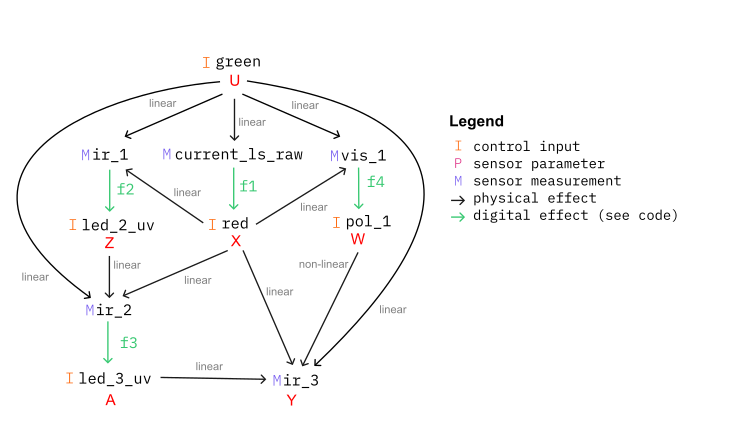

### Defining `f_1`, ..., `f_4`

You can use whatever you like, but here are two pre-implemented ones: a clamped linear function and a parametrizable sigmoid (the logistic function).

#### Clamped linear function

In [4]:
def clamped(x, a, b, lo, hi):
    return np.maximum(lo,np.minimum(hi, a*x + b))

The parameters `a`,`b` are the slope and intercept, `lo`,`hi` set the max/min values (at which clamping ocurrs).

#### Logistic function

In [5]:
def logistic(x, l, k, x0, b):
    return l / (1 + np.exp(-k * (x-x0))) + b    

The parameters `l`,`k`,`x0` and `b` allow you to change the shape of the function. See appendix for different function shapes.

### Collecting data

To understand the chamber / batch calls, please see the [documentation](https://docs.causalchamber.ai/remote-lab/running-a-real-time-experiment).

To sample using the `standard` configuration of the chamber ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_standard.pdf)).

In [6]:
def sample_standard(chamber, green, f1, f2, f3, f4):
    # Step 0: reset all inputs (see https://docs.causalchamber.ai/case-studies/causal-inference/generating-real-data-with-a-known-causal-structure#a-note-of-caution)
    batch = chamber.new_batch()
    batch.set('green', 0)
    batch.set('red', 0)
    batch.set('led_2_uv', 0)
    batch.set('pol_1', 0)
    batch.set('led_3_uv', 0)
    
    # Step 1: Set green, then measure
    batch = chamber.new_batch()
    batch.set('green', green)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 2: Set red (from step 1's measurement), then measure
    current_ls_raw = df.current_ls_raw
    red = round(f1(current_ls_raw))
    batch = chamber.new_batch()
    batch.set('red', red)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 3: Set led_2_uv and pol_1 (from step 2's measurement), then measure
    ir_1 = df.ir_1
    led_2_uv = round(f2(ir_1))
    vis_1 = df.vis_1
    pol_1 = f4(vis_1)
    batch = chamber.new_batch()
    batch.set('led_2_uv', led_2_uv)
    batch.set('pol_1', pol_1)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 4: Set led_3_uv (from step 3's measurement), then measure
    ir_2 = df.ir_2
    led_3_uv = round(f3(ir_2))
    batch = chamber.new_batch()
    batch.set('led_3_uv', led_3_uv)
    batch.measure(n=1)
    df = batch.submit().iloc[0]
    ir_3 = df.ir_3

    # Return data
    return pd.DataFrame({
        'green': [green],
        'current_ls_raw': [current_ls_raw],
        'red': [red],        
        'vis_1': [vis_1],
        'pol_1': [pol_1],
        'ir_1': [ir_1],
        'led_2_uv': [led_2_uv],
        'ir_2': [ir_2],
        'led_3_uv': [led_3_uv],
        'ir_3': [ir_3]
    })

To sample using the `linked_leds` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf)) or `linked_leds_sigmoid` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf)) configurations of the chamber.

In [7]:
def sample_linked(chamber, green, f1, f4):
    # Step 0: reset all inputs (see https://docs.causalchamber.ai/case-studies/causal-inference/generating-real-data-with-a-known-causal-structure#a-note-of-caution)
    batch = chamber.new_batch()
    batch.set('green', 0)
    batch.set('red', 0)
    batch.set('led_2_uv', 0)
    batch.set('pol_1', 0)
    batch.set('led_3_uv', 0)
    
    # Step 1: Set green, then measure
    batch = chamber.new_batch()
    batch.set('green', green)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 2: Set red (from step 1's measurement), then measure
    current_ls_raw = df.current_ls_raw
    red = round(f1(current_ls_raw))    
    batch = chamber.new_batch()
    batch.set('red', red)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 3: Set pol_1 (from step 2's measurement), then measure
    # NOTE: f2, f3 are computed by the chamber itself
    vis_1 = df.vis_1
    pol_1 = f4(vis_1)
    batch = chamber.new_batch()
    batch.set('pol_1', pol_1)
    batch.measure(n=1)
    df_last = batch.submit().iloc[0]

    # Return data
    return pd.DataFrame({
        'green': [green],
        'current_ls_raw': [current_ls_raw],
        'red': [red],
        'vis_1': [vis_1],
        'pol_1': [pol_1],
        'ir_1': [df_last.ir_1],
        'led_2_uv': [df_last.led_2_uv],
        'ir_2': [df_last.ir_2],
        'led_3_uv': [df_last.led_3_uv],
        'ir_3': [df_last.ir_3]
    })

Sample also for counterfactuals Y(0) and Y(1), with binary treatment A \in {0,255}

In [8]:
def sample_standard_binary_treatment_counterfactuals(chamber, green, f1, f2, f3, f4, max_confounding=False):
    # Step 0: reset all inputs (see https://docs.causalchamber.ai/case-studies/causal-inference/generating-real-data-with-a-known-causal-structure#a-note-of-caution)
    batch = chamber.new_batch()
    batch.set('green', 0)
    batch.set('blue', 0)
    batch.set('red', 0)
    batch.set('led_2_uv', 0)
    batch.set('pol_1', 0)
    batch.set('pol_2', 0)
    batch.set('led_3_uv', 0)

    # Maximise confounding U signal by maximising sensitvity of A and Y sensors, ir_2 and ir_3
    batch.set('diode_ir_2', 2 if max_confounding else 0) # max diode size
    batch.set('diode_ir_3', 2 if max_confounding else 0) # max diode size
    batch.set('t_ir_2', 3 if max_confounding else 0) # max exposure time
    batch.set('t_ir_3', 3 if max_confounding else 0) # max exposure time
    
    # Step 1: Set green, then measure
    batch = chamber.new_batch()
    if max_confounding:
        batch.set('blue', green) ### MAXIMISE CONFOUNDING: blue is stronger than green
    else:
        batch.set('green', green) ### MAXIMISE CONFOUNDING: blue is stronger than green
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 2: Set red (from step 1's measurement), then measure
    current_ls_raw = df.current_ls_raw
    red = round(f1(current_ls_raw))
    batch = chamber.new_batch()
    batch.set('red', red)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 3: Set led_2_uv and pol_1 (from step 2's measurement), then measure
    ir_1 = df.ir_1
    led_2_uv = round(f2(ir_1))
    vis_1 = df.vis_1
    pol_1 = f4(vis_1)
    batch = chamber.new_batch()
    batch.set('led_2_uv', led_2_uv)
    batch.set('pol_1', pol_1)
    pol_2 = 0 if max_confounding else pol_1 + 90
    batch.set('pol_2', pol_2)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 4: Set led_3_uv (from step 3's measurement), then measure
    # f3 = lambda x: logistic(x, l=4095, k=1e-3, x0=5000, b=0) # Logistic
    # A = 0 corresponds to led_3_uv = 0
    # A = 1 corresponds to led_3_uv = 2047
    A0_led_3_uv = 0
    A1_led_3_uv = 2047
    ir_2 = df.ir_2
    led_3_uv = round(f3(ir_2)) * A1_led_3_uv
    batch = chamber.new_batch()
    batch.set('led_3_uv', led_3_uv)
    batch.measure(n=1)
    df = batch.submit().iloc[0]
    ir_3 = df.ir_3

    # Step 5: Y(1), Y(0)
    batch = chamber.new_batch()
    batch.set('led_3_uv', A0_led_3_uv)
    batch.measure(n=1)
    df = batch.submit().iloc[0]
    Y0 = df.ir_3

    batch = chamber.new_batch()
    batch.set('led_3_uv', A1_led_3_uv) #max 4095
    batch.measure(n=1)
    df = batch.submit().iloc[0]
    Y1 = df.ir_3
    

    # Return data
    return pd.DataFrame({
        'green': [green],
        'current_ls_raw': [current_ls_raw],
        'red': [red],        
        'vis_1': [vis_1],
        'pol_1': [pol_1],
        'pol_2': [pol_2],
        'ir_1': [ir_1],
        'led_2_uv': [led_2_uv],
        'ir_2': [ir_2],
        'led_3_uv': [led_3_uv],
        'ir_3': [ir_3],
        'Y1': [Y1],
        'Y0': [Y0],
    })

Now, to collect a fresh dataset with `n` datapoints (after resetting the chamber)

In [48]:
CHAMBER_ID = 'lt-demo-ch4lu'

def sample(green, config, f1, f2, f3, f4, max_confounding=False, verbose=True):
    chamber = lab.Chamber(CHAMBER_ID, config, credentials_file = '/Users/jakobzeitler/Documents/CausalChambers/cc_key.txt')
    dfs = []
    n = len(green)
    print(f"max_confounding={max_confounding}")
    for i in range(n):
        print(f'Collecting datapoint {i+1}/{n}', end="\r") if verbose else None
        if config == 'standard':
            #observation = sample_standard(chamber, green[i], f1, f2, f3, f4)
            
            observation = sample_standard_binary_treatment_counterfactuals(chamber, green[i], f1, f2, f3, f4, max_confounding)
        elif config in ['linked_leds', 'linked_leds_sigmoid']:
            observation = sample_linked(chamber, green[i], f1, f4)
        else:
            raise Exception(f"Unrecognized chamber config {CHAMBER_CONFIG}")
        # Save the datapoint
        dfs.append(observation)
    return pd.concat(dfs, ignore_index=True)

## Example dataset

Let's begin by defining the functions. The parameters for `f2` and `f3` below are taken from the [linked_leds](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf) and [linked_leds_sigmoid](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf) configurations, where the chamber itself these functions. If you decide on this graph, you can switch `CHAMBER_CONFIG` to these configurations for faster data collection; if in doubt, ask Juan.

In [175]:
f1_linear = lambda x: clamped(x, -0.085, -1445, 0, 255) # linear clamped

f4 = lambda x: logistic(x, l=180, k=2e-3, x0=4000, b=-90)

# f2 and f3 as defined in the linked_leds and linked_leds_sigmoid configurations (see above).
# If using these chamber configs, these functions are computed by the chamber, which is a bit faster

# f2 = lambda x: logistic(x, l=4095, k=2e-4, x0=32768, b=0) # Logistic
f2_linear = lambda x: clamped(x, 0.0624, 0, 0, 4095) # linear clamped

# f3 = lambda x: logistic(x, l=4095, k=1e-3, x0=5000, b=0) # Logistic
f3 = lambda x: clamped(x, 5*0.0624, 0, 0, 4095) # linear clamped

#(arr >= 0).astype(int)
f3_binary = lambda x: (clamped(x, 5*0.0624, 0, 0, 4095) >= 4095/2).astype(int) # linear clamped, then 4095/2 threshold to binary
f3_binary_thr_1450 = lambda x: (clamped(x, 5*0.0624, 0, 0, 4095) >= 1450).astype(int) # linear clamped ir_2, then 1450 threshold to binary
f3_binary_thr_600 = lambda x: (clamped(x, 5*0.0624, 0, 0, 4095) >= 600).astype(int) # linear clamped ir_2, then 600 threshold to binary
f3_binary_cut = lambda x: (x < 5250).astype(int) # linear clamped, then 4095/2 threshold to binary

f1_non_linear = lambda x: logistic(x, l=255, k=2e-3, x0=-19000.0, b=0) # Logistic
f2_non_linear = lambda x: logistic(x, l=4095, k=1e-3, x0=35000.0, b=0) # Logistic ({"l": 4095, "k": 1e-3, "x0": 35000, "b": 0}, "f2_non_linear"),


Now, sample data for green (our source node) and run the sample function

**linked_leds** configuration

In [22]:
%%time
# Total datapoints
N = 300

# Sample green
rng = np.random.default_rng(981264976135)
green = rng.integers(0, 256, size=N)

df = sample(green, 'linked_leds', f1, f2, f3, f4)
# df = sample(green, 'linked_leds_sigmoid', f1, f2, f3, f4)


Contacting chamber lt-demo-ch4lu
  Resetting & verifying hardware (config: linked_leds)
  Done. (26.41 seconds)

    Causal Chamber® lt-demo-ch4lu
  ---------------------------------
       chamber_id : lt-demo-ch4lu
            model : Light Tunnel Mk2
    configuration : linked_leds
          version : 1.0
       session_id : bab181ee-45cf-42c6-9a50-f4f364e6987b
         endpoint : https://api.causalchamber.ai/v0
    documentation : http://box.causalchamber.ai/config_doc_lt_mk2_linked_leds.pdf
 codebase_version : 6ff41b2f00a0869d574444d6d1f1507d86f71859
        
CPU times: user 23 s, sys: 2.58 s, total: 25.5 s
Wall time: 17min 32s


In [69]:
#sns.pairplot(df)
1

1

In [24]:
df.to_csv("out.csv")

In [78]:
f3_binary_thr_1450(df["ir_2"]).describe()

count    300.000000
mean       0.503333
std        0.500824
min        0.000000
25%        0.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: ir_2, dtype: float64

<Axes: >

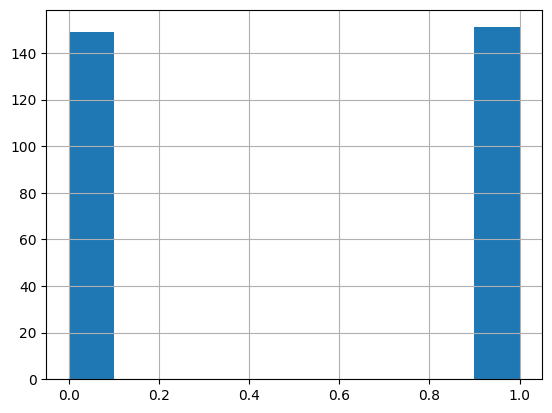

In [74]:
f3_binary_thr_90(df["led_3_uv"]).hist()

**standard** configuration

In [52]:
%%time
# Total datapoints
N = 3

#30minutes for 300 samples, so 10 samples, 1 minute; 1 sample, 6 seconds
# 5h 22min for 3000 samples
# 7h 23min for 4000 samples

# Sample green
rng = np.random.default_rng(981264976135)
green = rng.integers(0, 256, size=N)
max_confounding=True
df_std = sample(green, 'standard', f1, f2, f3_binary_thr_1450, f4, max_confounding=max_confounding)


Contacting chamber lt-demo-ch4lu
  Resetting & verifying hardware (config: standard)
  Done. (5.49 seconds)

    Causal Chamber® lt-demo-ch4lu
  ---------------------------------
       chamber_id : lt-demo-ch4lu
            model : Light Tunnel Mk2
    configuration : standard
          version : 1.1
       session_id : ea602ff8-aa47-4c8d-8d60-6b2e7fb5a98d
         endpoint : https://api.causalchamber.ai/v0
    documentation : http://box.causalchamber.ai/config_doc_lt_mk2_standard.pdf
 codebase_version : 6ff41b2f00a0869d574444d6d1f1507d86f71859
        
max_confounding=True
CPU times: user 648 ms, sys: 96.8 ms, total: 745 ms
Wall time: 22.9 s


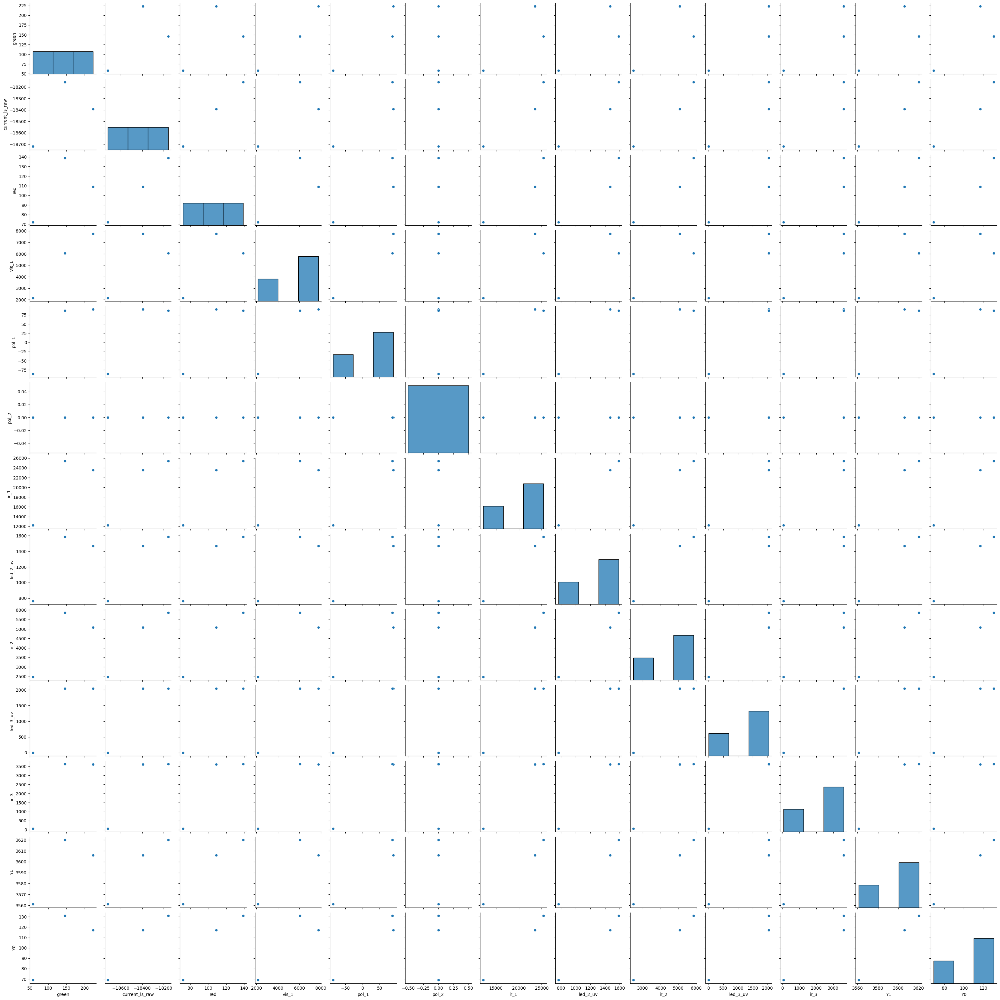

In [53]:
sns.pairplot(df_std)

In [54]:
len(df_std)

3

In [55]:
df_std["Y1"].mean()-df_std["Y0"].mean()

3490.0

In [56]:
df_std["pol_1"].values-df_std["pol_2"].values

array([ 89.90188239,  87.09998914, -85.69931591])

In [23]:
df_std.to_csv(f"out_binaryA_counterfactuals_max_confounding{max_confounding}.csv")

## Query Loop for Full Benchmark

In [176]:
settings = [
    {"title":"weak_confounding_linear","parameters":('standard', f1_linear, f2_linear, f3_binary_cut, f4, False)},
    {"title":"weak_confounding_non_linear","parameters":('standard', f1_non_linear, f2_non_linear, f3_binary_cut, f4, False)},
    {"title":"strong_confounding_linear","parameters":('standard', f1_linear, f2_linear, f3_binary_cut, f4, True)},
    {"title":"strong_confounding_non_linear","parameters":('standard', f1_non_linear, f2_non_linear, f3_binary_cut, f4, True)}
]

In [180]:
%%time
#30minutes for 300 samples, so 10 samples, 1 minute; 1 sample, 6 seconds
N = 1000
for s in settings:
    
    setting_name = s["title"]
    print(setting_name)
    # Total datapoints
    rng = np.random.default_rng(981264976135)
    confounder_state_LED = rng.integers(0, 256, size=N)
    parameters = (confounder_state_LED,) + s["parameters"]
    print(parameters)    
    df = sample(*parameters)

    #Sanity checks
    print(df["Y1"].mean()-df["Y0"].mean())
    print(df["pol_1"].values-df["pol_2"].values)

    #Save
    df.to_csv(f"out_binaryA_counterfactuals_{setting_name}.csv")

weak_confounding_linear
(array([223, 146,  58, 124,  81,  71, 213,  73, 143, 166,  83, 109, 244,
       109,  23, 174,  11, 158,  45, 106, 145,  37, 230, 126, 250,  93,
        29, 167, 101,  58, 214, 231,  27, 144, 205,  20, 232, 230, 209,
       227, 211, 200, 215,  27, 212,  46, 206, 147,  99, 250, 214,  89,
       175,  58, 200,  36,  41, 190,  29,  83, 126, 255,  72, 149,   6,
       191, 199, 240, 217,  51, 115,  18,  69,  15,  18, 184,  25, 179,
       154,  87,  43,  59,  64,  90, 118,  16, 119, 148,   2,   8, 144,
       119,  59, 129,  86, 157, 194,  49, 232, 223, 216, 151,  87, 196,
       211,  28, 158, 118,  56,  10, 185,  27,  15, 130, 151, 218, 222,
       117, 136, 196,  95,  97, 196, 104,  87,  53,  80,   4, 153, 104,
        15, 189, 233, 140, 127, 159,  33,  91,  42, 173,  19, 214,  18,
       196,  58, 133, 197, 240, 220, 134,  18,  47,  71, 222,  22, 105,
        71, 167, 248,  18, 165, 111,  64,  43,  90, 247,  86, 135, 238,
       155,  27, 100, 240, 111, 187,  2

In [178]:
weak_confounding_linear = "out_binaryA_counterfactuals_weak_confounding_linear.csv"
weak_confounding_non_linear = "out_binaryA_counterfactuals_weak_confounding_non_linear.csv"
strong_confounding_linear = "out_binaryA_counterfactuals_strong_confounding_linear.csv" 
strong_confounding_non_linear = "out_binaryA_counterfactuals_strong_confounding_non_linear.csv" 

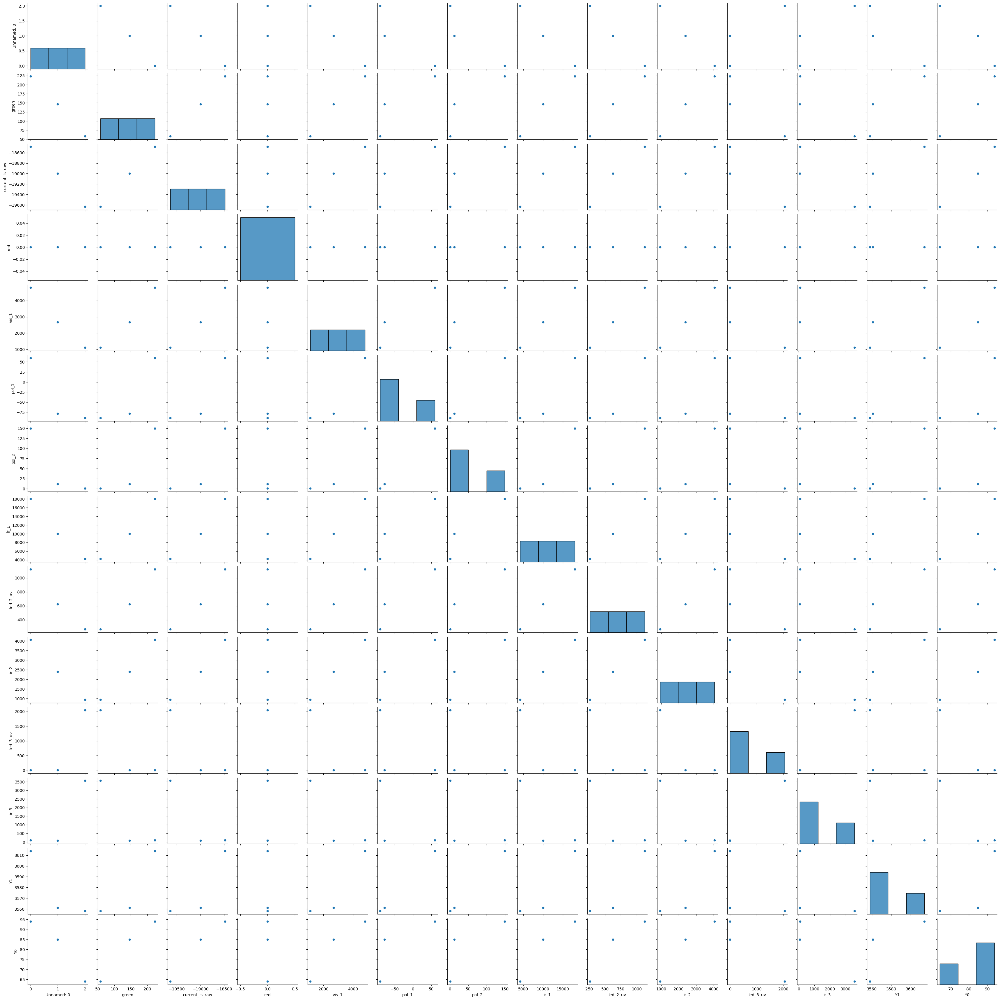

In [109]:
sns.pairplot(pd.read_csv(weak_confounding_linear))

XXXXXXXXXXXXXXXXX
out_binaryA_counterfactuals_weak_confounding_linear.csv


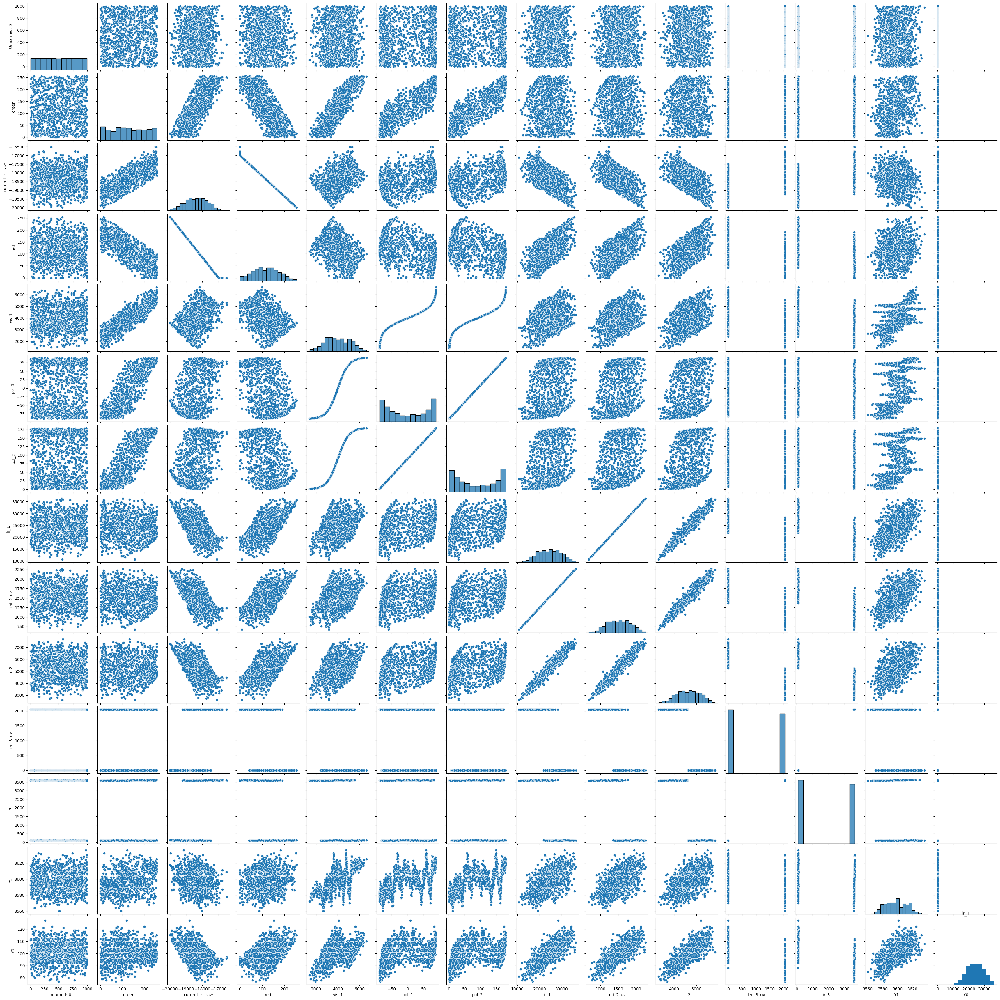

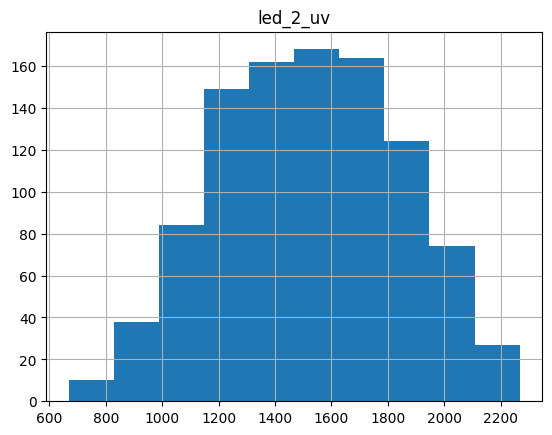

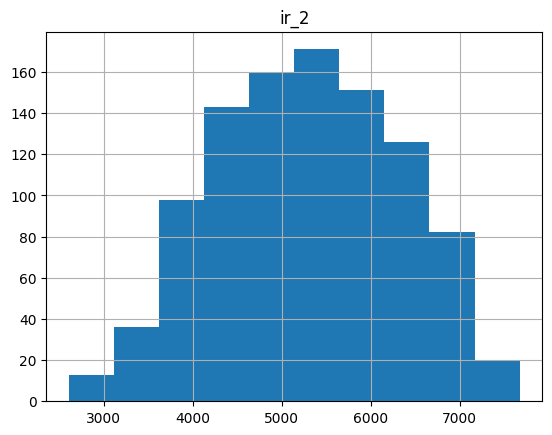

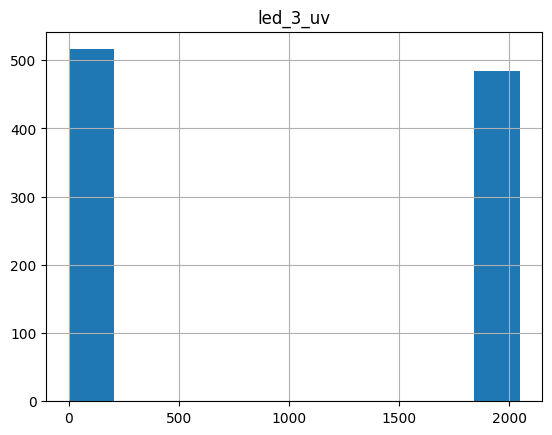

XXXXXXXXXXXXXXXXX
out_binaryA_counterfactuals_weak_confounding_non_linear.csv


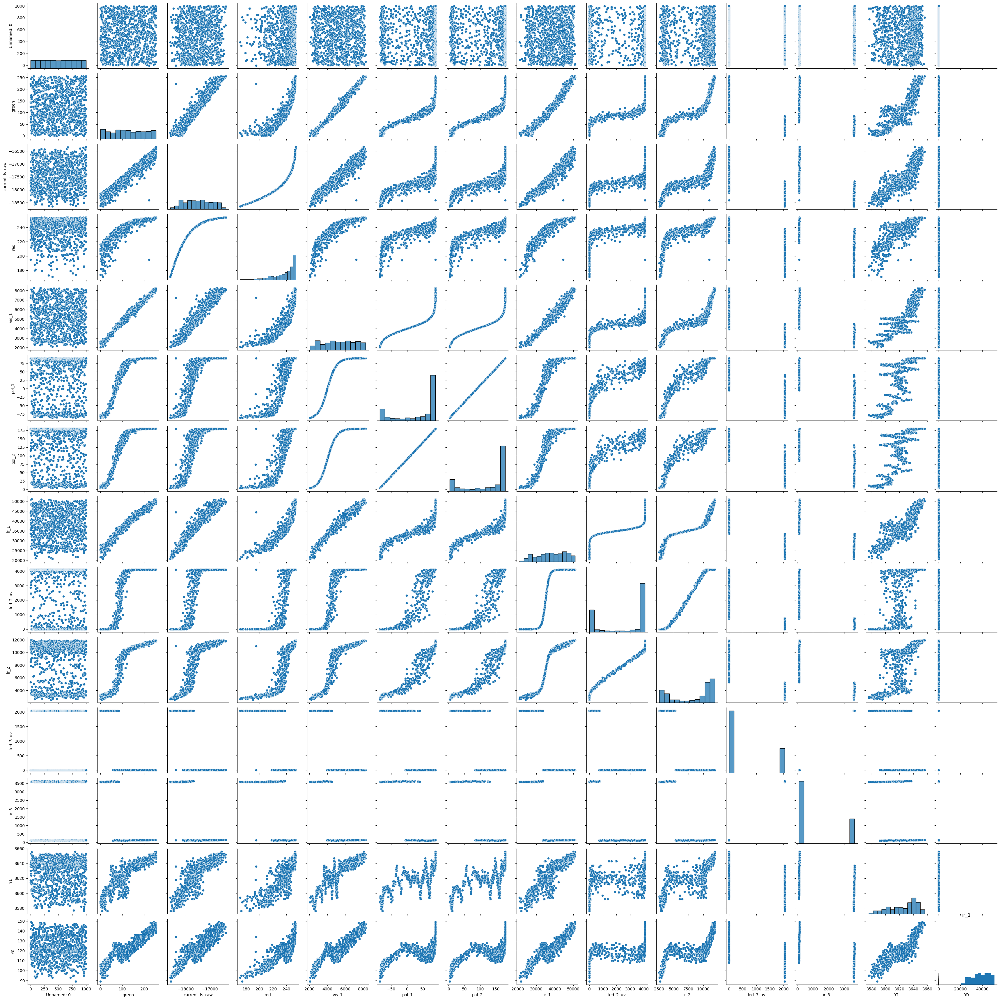

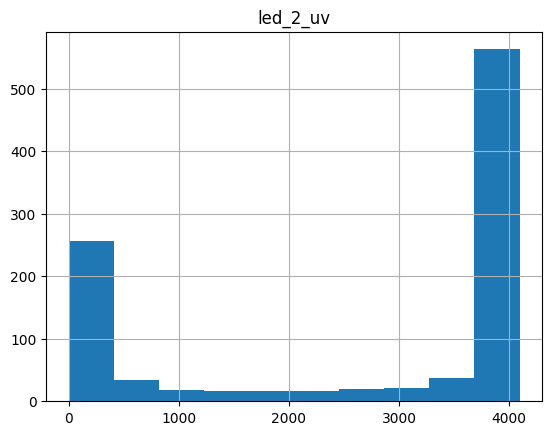

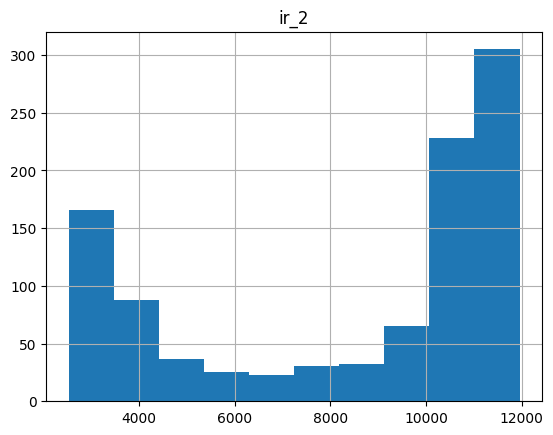

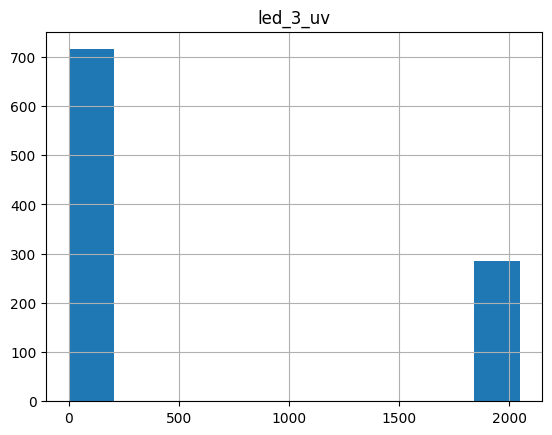

XXXXXXXXXXXXXXXXX
out_binaryA_counterfactuals_strong_confounding_linear.csv


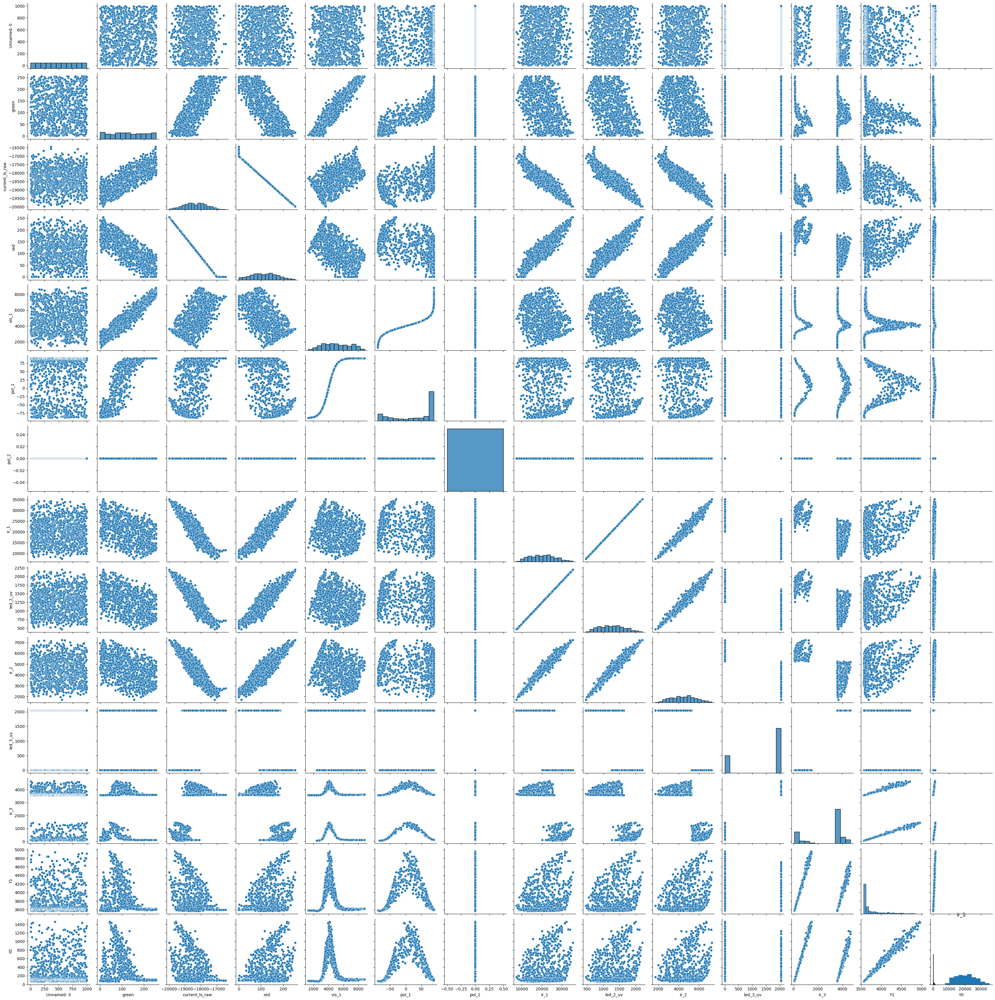

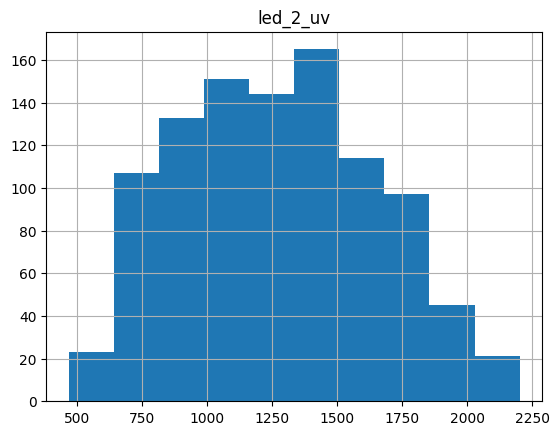

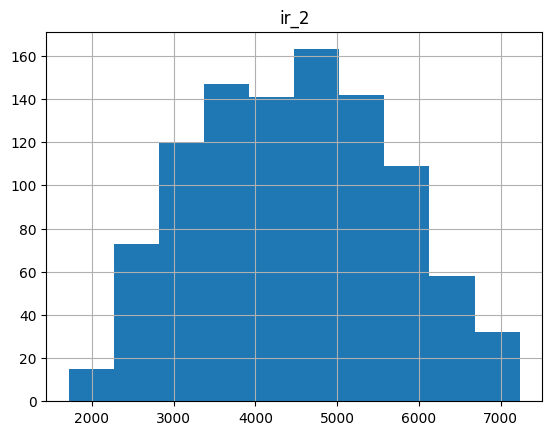

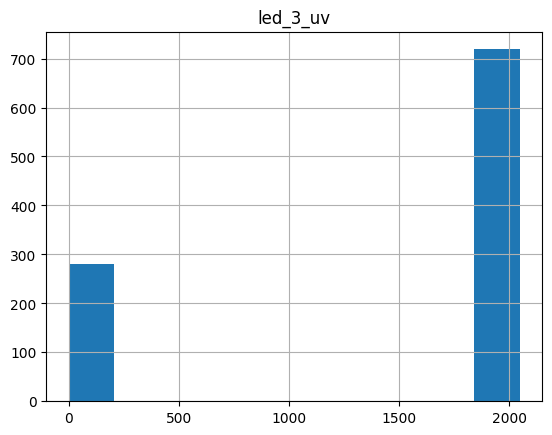

XXXXXXXXXXXXXXXXX
out_binaryA_counterfactuals_strong_confounding_non_linear.csv


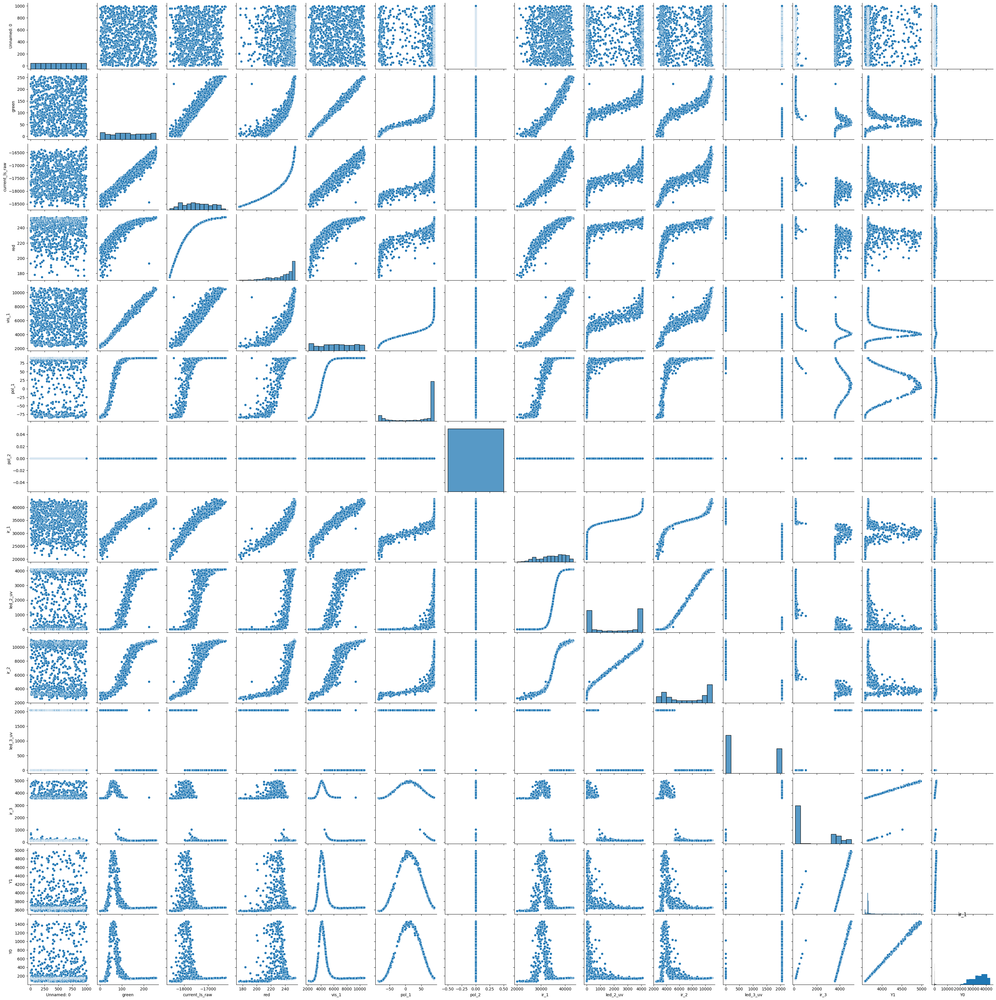

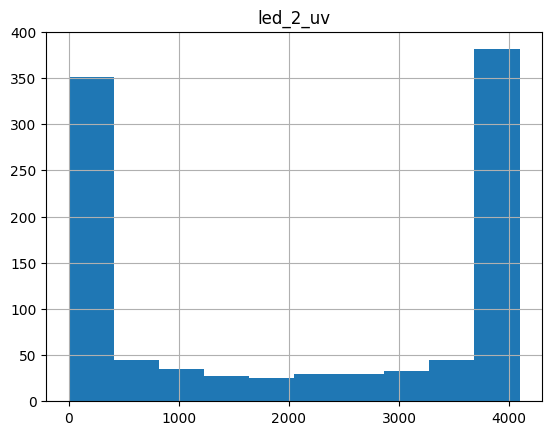

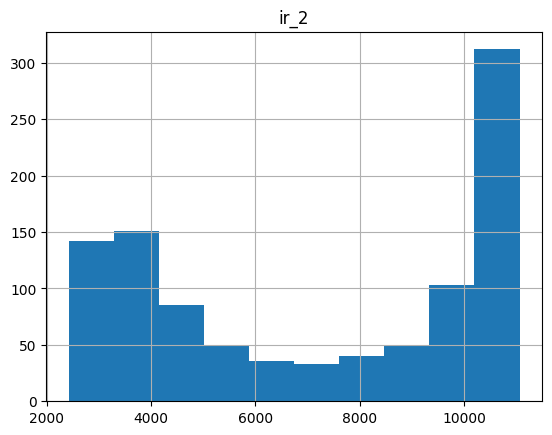

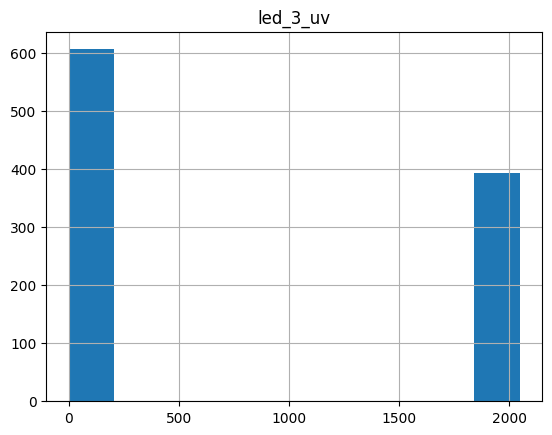

In [183]:
for s in [weak_confounding_linear,  weak_confounding_non_linear, strong_confounding_linear, strong_confounding_non_linear]:
    #for s in [strong_confounding_non_linear]:
    print("XXXXXXXXXXXXXXXXX")
    print(s)
    df = pd.read_csv(s)
    
    #print(f3(df["ir_2"]).describe())
    pairplot = sns.pairplot(df)
    #plt.show()
    #fig = pairplot.get_figure()
    pairplot.savefig(f"pairplot_{s.split(".")[0]}.png") 
    
    #(df["current_ls_raw"]).hist()
    #plt.title('current_ls_raw')
    #plt.show()

    #(f1_linear(df["current_ls_raw"])).hist()
    #plt.title('f1_linear(current_ls_raw)')
    #plt.show()

    #(df["red"]).hist()
    #plt.title('red')
    #plt.show()

    df["ir_1"].hist()
    plt.title('ir_1')
    plt.show()
    
    (df["led_2_uv"]).hist()
    plt.title('led_2_uv')
    plt.show()
    
    df["ir_2"].hist()
    plt.title('ir_2')
    plt.show()

    (df["led_3_uv"]).hist()
    plt.title('led_3_uv')
    plt.show()
    
    #f3_binary_cut(df["ir_2"]).hist()
    #plt.title('ir_2')
    #plt.show()
    
    #(df["led_3_uv"]).hist()
    #plt.title('led_3_uv')
    #plt.show()
    

## Appendix

The logistic function for different values of the parameters. You can use this code to experiment with different values.

Text(0, 0.5, '$f_n$(x)')

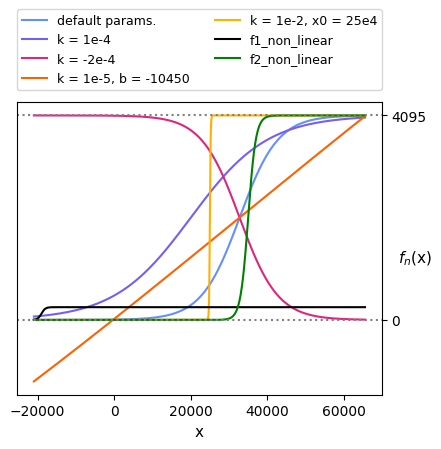

In [167]:
colors = ["#648FFF", "#785EF0", "#DC267F", "#FE6100", "#FFB000", "black", "green", "blue"]  # IBM colorblind palette

curves = [
    ({"l": 4095, "k": 2e-4, "x0": 32768, "b": 0}, "default params."),
    ({"l": 4095, "k": 1e-4, "x0": 20_000, "b": 0}, "k = 1e-4"),
    ({"l": 4095, "k": -2e-4, "x0": 32768, "b": 0}, "k = -2e-4"),
    ({"l": 25_000, "k": 1e-5, "x0": 32768, "b": -10450}, "k = 1e-5, b = -10450"),
    ({"l": 4095, "k": 1e-2, "x0": 25_000, "b": 0}, "k = 1e-2, x0 = 25e4"),
    #({"l": 4095, "k": 0, "x0": 32768, "b": 0}, "k = 0"),
    ({"l": 255, "k": 2e-3, "x0": -19000, "b": 0}, "f1_non_linear"),
    ({"l": 4095, "k": 1e-3, "x0": 35000, "b": 0}, "f2_non_linear"),
    #f1_non_linear = lambda x: logistic(x, l=255, k=2e-3, x0=-18250.0, b=0) # Logistic
]

x = np.linspace(-21e3, 2**16 - 1, 10_000)
#x = np.linspace(-21e3, -17000, 10_000)

fig, ax = plt.subplots(figsize=(4.7, 3.8))

for i, (params, label) in enumerate(curves):
    ax.plot(x, logistic(x, **params), color=colors[i], label=label)

ax.axhline(0, color="gray", linestyle=":")
ax.axhline(4095, color="gray", linestyle=":")
ax.yaxis.tick_right()
ax.yaxis.set_label_position('right')
ax.set_yticks([0, 4095])
ax.legend(fontsize=9, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2)
ax.set_xlabel('x', fontsize=11)
ax.set_ylabel('$f_n$(x)', rotation=0, ha='right', fontsize=11)
# plt.savefig('sigmoids_params.pdf', dpi=200, bbox_inches='tight')